[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_tails/BA_L2_tails.ipynb)

# BA_L2_tails: Tail Plot and Hill Plot

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Empirical survival function of standardised daily losses of Bitcoin and the S&P 500 on log-log scales against the Normal, and the Hill estimator of the tail index as a function of the number of order statistics with 95% bands, daily log returns 1 January 2018 to 18 September 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

Far in the tail, losses $L = -r$ follow a power law, $P(L > x) \approx c\,x^{-\alpha}$; $\alpha$ is the **tail index**.
A smaller $\alpha$ means a heavier tail; moments of order $q \ge \alpha$ are infinite, so $\alpha < 4$ means infinite
kurtosis. The **Hill estimator** uses the $k$ largest losses $L_{(1)} \ge \dots \ge L_{(k+1)}$:

$$\hat\alpha(k) = \Bigg[\frac1k\sum_{i=1}^{k} \ln\frac{L_{(i)}}{L_{(k+1)}}\Bigg]^{-1}, \qquad \text{95\% band: } \hat\alpha\Big(1 \pm \frac{1.96}{\sqrt k}\Big).$$

Data: daily log returns in percent, 1 January 2018 to 18 September 2026, every close in the EODHD files.

**How to read the chart.** Left: the empirical probability that the standardised loss exceeds $x$; a power-law tail
is a straight line with slope $-\alpha$, while the Normal (red) bends down. Right: $\hat\alpha$ against $k$ as a share
of $n$; small $k$ uses few observations (wide bands), large $k$ lets the centre of the distribution bias $\hat\alpha$
downwards. The estimate is read on the flat part, here $k \approx 2.5\%$.

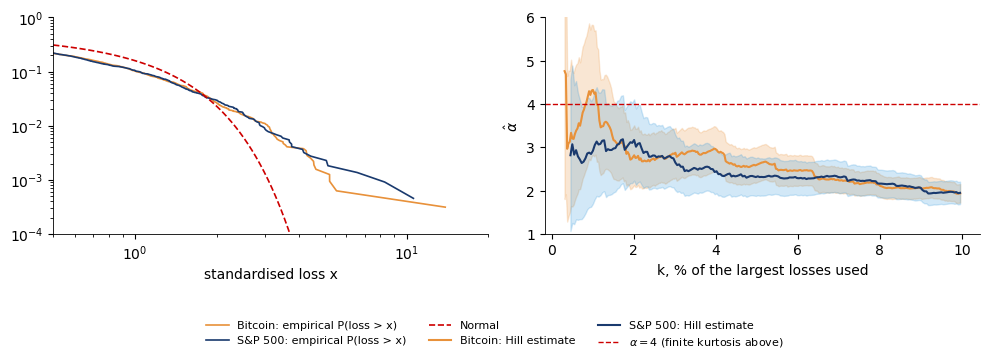

In [5]:
from scipy import stats

R = {'Bitcoin': rets(prices('BTC-USD.CC')), 'S&P 500': rets(prices('GSPC.INDX'))}
BAND = {'Bitcoin': BTC, 'S&P 500': '#3498DB'}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xs = np.logspace(np.log10(0.5), np.log10(15), 100)
for k, col in [('Bitcoin', BTC), ('S&P 500', BLUE)]:
    r = R[k]; L = np.sort(-(r - r.mean()) / r.std())[::-1]; L = L[L > 0]
    ax[0].loglog(L, np.arange(1, len(L) + 1) / len(r), color=col, lw=1.2, label=f'{k}: empirical P(loss > x)')
ax[0].loglog(xs, stats.norm.sf(xs), color=RED, ls='--', lw=1.2, label='Normal')
ax[0].set_xlabel('standardised loss x'); ax[0].set_ylim(1e-4, 1); ax[0].set_xlim(0.5, 20)
hill = {}
for k, col in [('Bitcoin', BTC), ('S&P 500', BLUE)]:
    r = R[k]; L = np.sort(-r.values)[::-1]
    ks = np.arange(10, int(0.10 * len(r)))
    a = np.array([1 / np.mean(np.log(L[:kk] / L[kk])) for kk in ks])
    hill[k] = (ks, a)
    ax[1].plot(ks / len(r) * 100, a, color=col, label=f'{k}: Hill estimate')
    ax[1].fill_between(ks / len(r) * 100, a * (1 - 1.96 / np.sqrt(ks)), a * (1 + 1.96 / np.sqrt(ks)), color=BAND[k], alpha=0.22)
ax[1].axhline(4, color=RED, ls='--', lw=1, label=r'$\alpha = 4$ (finite kurtosis above)')
ax[1].set_xlabel('k, % of the largest losses used'); ax[1].set_ylabel(r'$\hat\alpha$'); ax[1].set_ylim(1, 6)
slide_legend(fig, 0.16)
save_fig(fig, 'ba_l2_tails')

In [6]:
tab = pd.DataFrame({k: {f'Hill alpha, k = {pc}% of n': a[np.argmin(abs(ks - pc / 100 * len(R[k])))] for pc in [1, 2.5, 5, 10]}
                    for k, (ks, a) in hill.items()}).T
tab.insert(0, 'n', [len(R[k]) for k in tab.index])
print(tab.round(2).to_string())

            n  Hill alpha, k = 1% of n  Hill alpha, k = 2.5% of n  Hill alpha, k = 5% of n  Hill alpha, k = 10% of n
Bitcoin  3183                     4.33                       2.71                     2.60                      1.94
S&P 500  2190                     2.92                       2.81                     2.32                      1.95
